<a href="https://colab.research.google.com/github/mrayhanz/244107020027-Machine-Learning/blob/main/Minggu%2015/MRayhanZamzami_JS15_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# IDENTITAS DIRI

Nama : Muhammad Rayhan Zamzami

NIM : 244107020027

Kelas : TI-3G

Absen : 19

# PRAKTIKUM 1 - Klasifikasi Day vs Night (HOG + Neural Network)

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2
import os
import pickle

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

train_dir = 'dataset/images/training' if os.path.exists('dataset/images/training') else '../Minggu 11/dataset/images/training'
test_dir = 'dataset/images/test' if os.path.exists('dataset/images/test') else '../Minggu 11/dataset/images/test'
print('Train dir:', train_dir)
print('Test dir :', test_dir)

Train dir: ../Minggu 11/dataset/images/training
Test dir : ../Minggu 11/dataset/images/test


In [2]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []
    for folder in p.glob('*'):
        if folder.is_dir():
            label = folder.name
            for file in folder.glob('*.jpg'):
                img = cv2.imread(str(file))
                if img is not None:
                    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
                    img_list.append((img, label))
    return img_list

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing: {len(test_img)}")

Jumlah data training: 240
Jumlah data testing: 160


In [3]:
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)

def label_encoder(label):
    return 1 if label == 'day' else 0

def preprocess(img_list):
    X, y = [], []
    for img, label in img_list:
        X.append(resize_image(img))
        y.append(label_encoder(label))
    return X, y

X_train_img, y_train = preprocess(train_img)
X_test_img, y_test = preprocess(test_img)
print('Dimensi data latih:', len(X_train_img))
print('Dimensi data uji  :', len(X_test_img))

Dimensi data latih: 240
Dimensi data uji  : 160


In [4]:
def extract_hog(X_imgs):
    feats = []
    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
        hog_feat = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False,
            feature_vector=True
        )
        feats.append(hog_feat)
    return np.array(feats)

X_train_feat = extract_hog(X_train_img)
X_test_feat = extract_hog(X_test_img)
print('Dimensi fitur HOG train:', X_train_feat.shape)
print('Dimensi fitur HOG test :', X_test_feat.shape)

Dimensi fitur HOG train: (240, 34596)
Dimensi fitur HOG test : (160, 34596)


In [5]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

y_train = np.array(y_train)
y_val = np.array(y_val)
y_test = np.array(y_test)
print('Train:', X_train.shape, '| Val:', X_val.shape, '| Test:', X_test_scaled.shape)

Train: (192, 34596) | Val: (48, 34596) | Test: (160, 34596)


In [6]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [7]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/20


1/6 ━━━━━━━━━━━━━━━━━━━━ 9s 2s/step - accuracy: 0.5000 - loss: 0.9008

2/6 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step - accuracy: 0.5781 - loss: 1.1733

3/6 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.6354 - loss: 1.1020

4/6 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/step - accuracy: 0.7109 - loss: 0.8840

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.7969 - loss: 0.6590

... (134 outputs left out)

4/6 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 1.0000 - loss: 4.2040e-07

5/6 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 1.0000 - loss: 1.4339e-06

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 1.0000 - loss: 1.1981e-06

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 1.0000 - loss: 1.1981e-06 - val_accuracy: 0.9792 - val_loss: 0.3716


In [8]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print("Akurasi Test:", test_acc)

Akurasi Test: 0.856249988079071


In [9]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred, target_names=['night', 'day']))
print(confusion_matrix(y_test, y_pred))

1/5 ━━━━━━━━━━━━━━━━━━━━ 0s 148ms/step

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step 


              precision    recall  f1-score   support

       night       0.86      0.85      0.86        80
         day       0.85      0.86      0.86        80

    accuracy                           0.86       160
   macro avg       0.86      0.86      0.86       160
weighted avg       0.86      0.86      0.86       160

[[68 12]
 [11 69]]


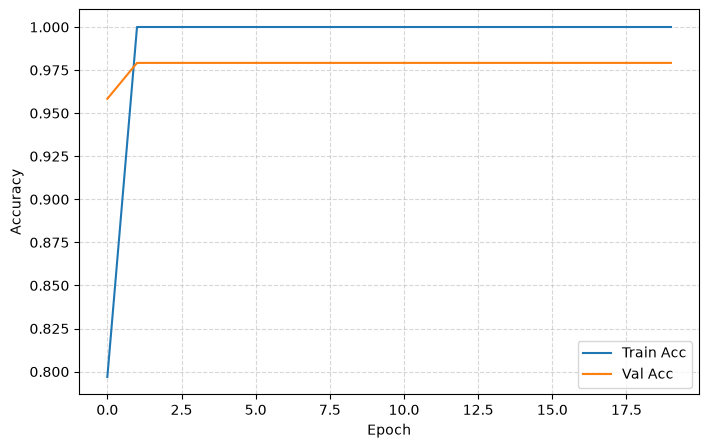

In [10]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [11]:
model.save('day_night_model.h5')
print('Model berhasil disimpan sebagai: day_night_model.h5')

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print('Scaler berhasil disimpan sebagai: scaler.pkl')

Model berhasil disimpan sebagai: day_night_model.h5
Scaler berhasil disimpan sebagai: scaler.pkl
